# CONTROLLED THREE-ALGORITHM COMPARISON
# SAME DATA, SAME FEATURES, SAME k RANGE

In [1]:
# ============================================================
# CONTROLLED THREE-ALGORITHM COMPARISON
# SAME DATA, SAME FEATURES, SAME k RANGE
# ============================================================

import pandas as pd
import numpy as np

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# ------------------------------------------------------------
# Load preprocessed data
# ------------------------------------------------------------

X = pd.read_csv(
    "/home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/data/Bipolar_preprocessed.csv"
)

print("Dataset shape:", X.shape)

# ------------------------------------------------------------
# Evaluate all algorithms for k = 2...10
# ------------------------------------------------------------

results = []

for k in range(2, 11):

    # -------------------------
    # K-Means
    # -------------------------

    km = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )

    km_labels = km.fit_predict(X)

    results.append({
        "Algorithm": "K-Means",
        "k": k,
        "Silhouette": silhouette_score(X, km_labels),
        "Davies_Bouldin": davies_bouldin_score(X, km_labels),
        "Calinski_Harabasz": calinski_harabasz_score(X, km_labels),
        "WCSS": km.inertia_
    })

    # -------------------------
    # Hierarchical
    # -------------------------

    hc = AgglomerativeClustering(
        n_clusters=k,
        metric="euclidean",
        linkage="ward"
    )

    hc_labels = hc.fit_predict(X)

    results.append({
        "Algorithm": "Hierarchical",
        "k": k,
        "Silhouette": silhouette_score(X, hc_labels),
        "Davies_Bouldin": davies_bouldin_score(X, hc_labels),
        "Calinski_Harabasz": calinski_harabasz_score(X, hc_labels),
        "WCSS": np.nan
    })

    # -------------------------
    # GMM
    # -------------------------

    gmm = GaussianMixture(
        n_components=k,
        random_state=42
    )

    gmm_labels = gmm.fit_predict(X)

    results.append({
        "Algorithm": "GMM",
        "k": k,
        "Silhouette": silhouette_score(X, gmm_labels),
        "Davies_Bouldin": davies_bouldin_score(X, gmm_labels),
        "Calinski_Harabasz": calinski_harabasz_score(X, gmm_labels),
        "WCSS": np.nan
    })

results_df = pd.DataFrame(results)

print("\nCONTROLLED COMPARISON")
display(results_df.round(6))

/usr/lib/python3/dist-packages/pytz/__init__.py:31: SyntaxWarning: invalid escape sequence '\s'
  match = re.match("^#\s*version\s*([0-9a-z]*)\s*$", line)


Dataset shape: (342, 168)

CONTROLLED COMPARISON


,Algorithm,k,Silhouette,Davies_Bouldin,Calinski_Harabasz,WCSS
0,K-Means,2,0.290191,1.515143,120.438207,5248.705543
1,Hierarchical,2,0.364764,0.888365,123.547208,NaN
2,GMM,2,0.290191,1.515143,120.438207,NaN
3,K-Means,3,0.265246,1.432613,124.618042,4096.308739
4,Hierarchical,3,0.245421,1.645275,114.865810,NaN
5,GMM,3,0.265246,1.432613,124.618042,NaN
6,K-Means,4,0.270647,1.384013,113.438811,3541.840562
7,Hierarchical,4,0.267813,1.394553,111.896884,NaN
8,GMM,4,0.270647,1.384013,113.438811,NaN
9,K-Means,5,0.163465,2.353396,84.065992,3557.862619


# CONTROLLED COMPARISON: BEST RESULTS

In [2]:
# ============================================================
# CONTROLLED COMPARISON: BEST RESULTS
# ============================================================

for algorithm in results_df["Algorithm"].unique():

    subset = results_df[
        results_df["Algorithm"] == algorithm
    ]

    print("\n========================================")
    print(algorithm)
    print("========================================")

    print("\nBest Silhouette:")
    display(
        subset.loc[
            subset["Silhouette"].idxmax()
        ]
    )

    print("Best Davies-Bouldin:")
    display(
        subset.loc[
            subset["Davies_Bouldin"].idxmin()
        ]
    )

    print("Best Calinski-Harabasz:")
    display(
        subset.loc[
            subset["Calinski_Harabasz"].idxmax()
        ]
    )


K-Means

Best Silhouette:


Algorithm                K-Means
k                              2
Silhouette              0.290191
Davies_Bouldin          1.515143
Calinski_Harabasz     120.438207
WCSS                 5248.705543
Name: 0, dtype: object

Best Davies-Bouldin:


Algorithm                K-Means
k                              4
Silhouette              0.270647
Davies_Bouldin          1.384013
Calinski_Harabasz     113.438811
WCSS                 3541.840562
Name: 6, dtype: object

Best Calinski-Harabasz:


...

Algorithm                   GMM
k                             2
Silhouette             0.290191
Davies_Bouldin         1.515143
Calinski_Harabasz    120.438207
WCSS                        NaN
Name: 2, dtype: object

Best Davies-Bouldin:


Algorithm                   GMM
k                             4
Silhouette             0.270647
Davies_Bouldin         1.384013
Calinski_Harabasz    113.438811
WCSS                        NaN
Name: 8, dtype: object

Best Calinski-Harabasz:


Algorithm                   GMM
k                             3
Silhouette             0.265246
Davies_Bouldin         1.432613
Calinski_Harabasz    124.618042
WCSS                        NaN
Name: 5, dtype: object

# K-MEANS vs GMM CLUSTER AGREEMENT


In [3]:
# ============================================================
# K-MEANS vs GMM CLUSTER AGREEMENT
# ============================================================

from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

km = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

gmm = GaussianMixture(
    n_components=3,
    random_state=42
)

km_labels = km.fit_predict(X)
gmm_labels = gmm.fit_predict(X)

ari = adjusted_rand_score(
    km_labels,
    gmm_labels
)

nmi = normalized_mutual_info_score(
    km_labels,
    gmm_labels
)

print("K-Means vs GMM agreement")
print("-------------------------")
print(f"Adjusted Rand Index : {ari:.6f}")
print(f"Normalized MI       : {nmi:.6f}")

print("\nContingency table:")
display(
    pd.crosstab(
        km_labels,
        gmm_labels,
        rownames=["K-Means"],
        colnames=["GMM"]
    )
)

K-Means vs GMM agreement
-------------------------
Adjusted Rand Index : 1.000000
Normalized MI       : 1.000000

Contingency table:


GMM,0,1,2
K-Means,,,
0,41,0,0
1,0,106,0
2,0,0,195


# CLUSTER STABILITY: K-MEANS AND GMM


In [4]:
# ============================================================
# CLUSTER STABILITY: K-MEANS AND GMM
# ============================================================

from sklearn.metrics import adjusted_rand_score

seeds = [0, 1, 2, 3, 4, 5, 10, 20, 42, 100]

reference_km = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
).fit_predict(X)

reference_gmm = GaussianMixture(
    n_components=3,
    random_state=42
).fit_predict(X)

stability_results = []

for seed in seeds:

    km_labels = KMeans(
        n_clusters=3,
        random_state=seed,
        n_init="auto"
    ).fit_predict(X)

    gmm_labels = GaussianMixture(
        n_components=3,
        random_state=seed
    ).fit_predict(X)

    stability_results.append({
        "Seed": seed,
        "KMeans_ARI_vs_seed42":
            adjusted_rand_score(reference_km, km_labels),
        "GMM_ARI_vs_seed42":
            adjusted_rand_score(reference_gmm, gmm_labels)
    })

stability_df = pd.DataFrame(stability_results)

print("Cluster stability against seed=42:")
display(stability_df.round(6))

print("\nMean stability:")
print(
    "K-Means:",
    stability_df["KMeans_ARI_vs_seed42"].mean()
)

print(
    "GMM:",
    stability_df["GMM_ARI_vs_seed42"].mean()
)

Cluster stability against seed=42:


,Seed,KMeans_ARI_vs_seed42,GMM_ARI_vs_seed42
0,0,0.989532,0.989532
1,1,0.989532,0.989532
2,2,1.000000,1.000000
3,3,1.000000,1.000000
4,4,1.000000,1.000000
5,5,0.989532,0.989532
6,10,0.989532,0.989532
7,20,1.000000,1.000000
8,42,1.000000,1.000000
9,100,0.699243,0.699243



Mean stability:
K-Means: 0.965736921694113
GMM: 0.965736921694113


# MISSINGNESS / UNKNOWN FEATURE INFLUENCE


In [5]:
# ============================================================
# MISSINGNESS / UNKNOWN FEATURE INFLUENCE
# ============================================================

unknown_features = [
    col for col in X.columns
    if "_Unknown" in col
]

print("Number of _Unknown features:", len(unknown_features))

print("\nUnknown-feature names:")
for col in unknown_features:
    print(col)

# Percentage of observations represented by Unknown indicators
unknown_rates = X[unknown_features].mean().sort_values(
    ascending=False
)

print("\nHighest Unknown proportions:")
display(
    unknown_rates.head(30).round(4)
)

Number of _Unknown features: 64

Unknown-feature names:
gender_Unknown
marital_status_Unknown
lifetime_history_of_rapid_cycling_Unknown
interepisodic_remission_Unknown
ever_manic_Unknown
persistent_elevated_mood_Unknown
persistent_irritability_Unknown
dec_need_for_sleep_Unknown
inc_speech_rate_and_amount_Unknown
racing_thoughts_Unknown
distractibility_Unknown
pma_mania_Unknown
grandiosity_Unknown
overfamiliarity_Unknown
increased_sexual_interest_Unknown
agitation_Unknown
high_risk_behaviours_Unknown
ever_depressive_Unknown
low_mood_Unknown
emptiness_Unknown
anhedonia_Unknown
executive_dysfunction_Unknown
guilt_Unknown
worthless_Unknown
poor_concentration_Unknown
self_harm_ideation_Unknown
suicidal_attempt_Unknown
ever_psychotic_Unknown
psychotic_symptoms_index_episode_Unknown
del_ref_Unknown
del_per_Unknown
del_gran_Unknown
del_sin_Unknown
del_ctrl_Unknown
del_soma_Unknown
thought_phen_Unknown
ah_Unknown
vh_Unknown
disorg_speech_Unknown
disorg_behaviour_Unknown
catatonia_Unknown
avolit

guilt_Unknown                                     0.4298
emptiness_Unknown                                 0.4269
worthless_Unknown                                 0.4269
self_harm_ideation_Unknown                        0.4240
anhedonia_Unknown                                 0.4211
poor_concentration_Unknown                        0.4211
antipsychotic_Unknown                             0.4211
suicidal_attempt_Unknown                          0.4181
psychotic_symptoms_index_episode_Unknown          0.4181
executive_dysfunction_Unknown                     0.4181
low_mood_Unknown                                  0.4123
vh_Unknown                                        0.2778
del_soma_Unknown                                  0.2778
thought_phen_Unknown                              0.2778
del_ctrl_Unknown                                  0.2778
disorg_speech_Unknown                             0.2778
ah_Unknown                                        0.2778
catatonia_Unknown              

# SENSITIVITY ANALYSIS:
# REMOVE _Unknown FEATURES


In [6]:
# ============================================================
# SENSITIVITY ANALYSIS:
# REMOVE _Unknown FEATURES
# ============================================================

X_no_unknown = X.drop(
    columns=unknown_features
)

print("Original shape:", X.shape)
print("Without _Unknown features:", X_no_unknown.shape)

for algorithm_name, model in [

    (
        "K-Means",
        KMeans(
            n_clusters=3,
            random_state=42,
            n_init="auto"
        )
    ),

    (
        "Hierarchical",
        AgglomerativeClustering(
            n_clusters=3,
            metric="euclidean",
            linkage="ward"
        )
    ),

    (
        "GMM",
        GaussianMixture(
            n_components=3,
            random_state=42
        )
    )
]:

    labels = model.fit_predict(X_no_unknown)

    print("\n===================================")
    print(algorithm_name)
    print("===================================")

    print(
        "Silhouette:",
        round(silhouette_score(X_no_unknown, labels), 6)
    )

    print(
        "Davies-Bouldin:",
        round(davies_bouldin_score(X_no_unknown, labels), 6)
    )

    print(
        "Calinski-Harabasz:",
        round(calinski_harabasz_score(X_no_unknown, labels), 6)
    )

    print(
        "Cluster sizes:",
        pd.Series(labels).value_counts().sort_index().to_dict()
    )

Original shape: (342, 168)
Without _Unknown features: (342, 104)

K-Means
Silhouette: 0.163254
Davies-Bouldin: 2.001378
Calinski-Harabasz: 59.546689
Cluster sizes: {0: 44, 1: 180, 2: 118}

Hierarchical
Silhouette: 0.155386
Davies-Bouldin: 1.978658
Calinski-Harabasz: 56.701241
Cluster sizes: {0: 192, 1: 112, 2: 38}

GMM
Silhouette: 0.163254
Davies-Bouldin: 2.001378
Calinski-Harabasz: 59.546689
Cluster sizes: {0: 44, 1: 180, 2: 118}


Figures will be saved to: /home/abhajkhan/Code/mca-tkmce/bipolar-disorder-severity-assessment-system/notebooks/ppt_outputs/comparison


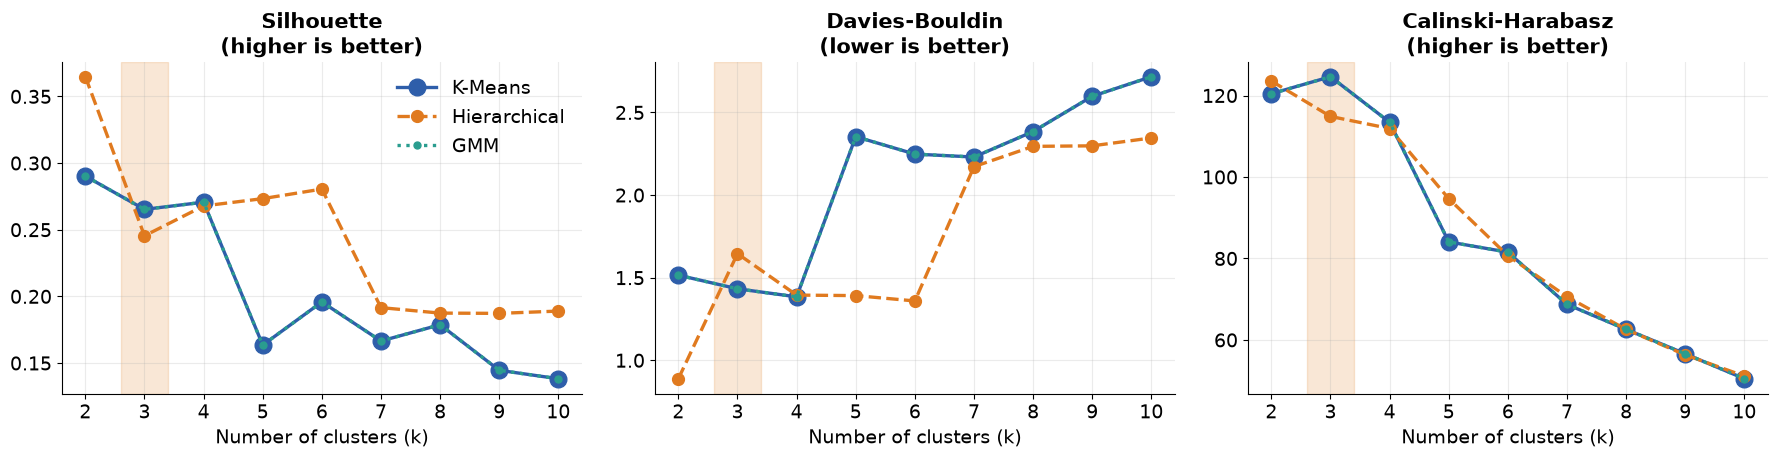

saved -> ppt_outputs/comparison/01_metrics_vs_k.png


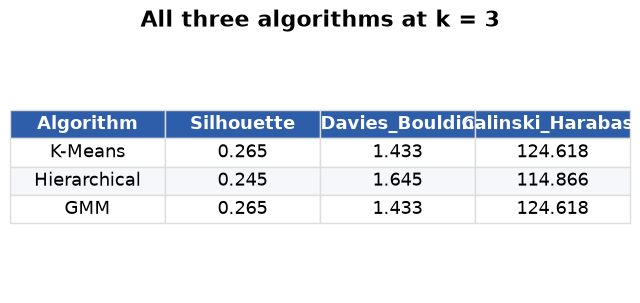

saved -> ppt_outputs/comparison/02_table_k3.png


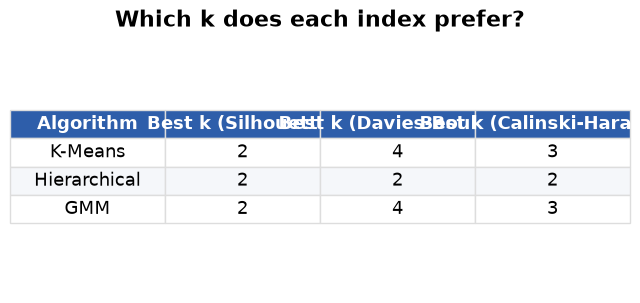

saved -> ppt_outputs/comparison/03_best_k.png


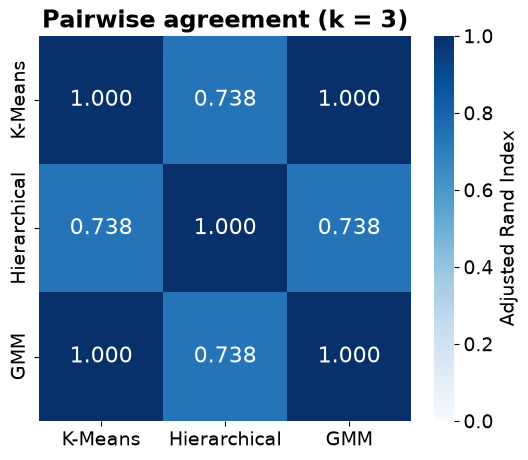

saved -> ppt_outputs/comparison/04_pairwise_ari.png


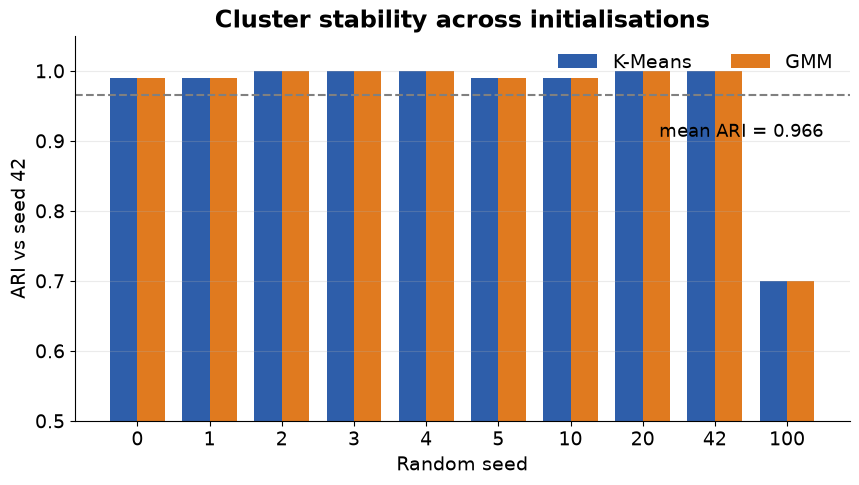

saved -> ppt_outputs/comparison/05_stability.png


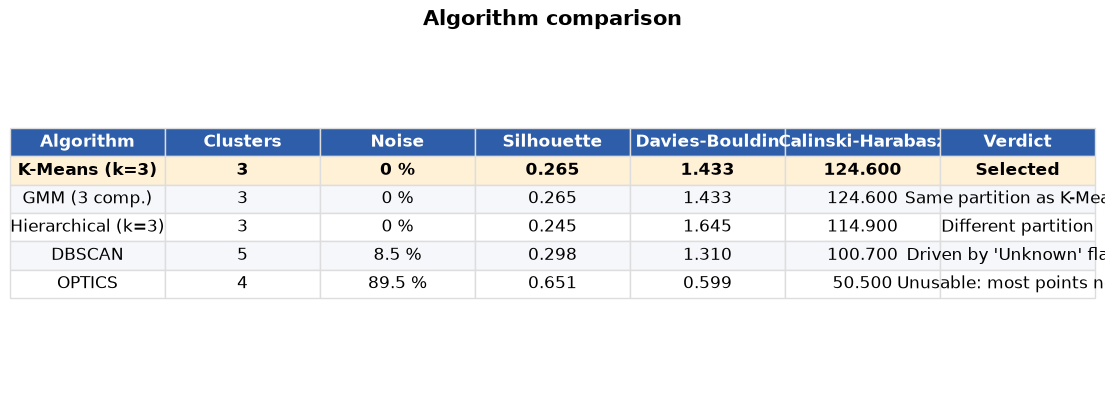

saved -> ppt_outputs/comparison/06_final_summary.png


In [7]:
# ===== Append to the END of the BD-comparison notebook (needs results_df and X from it) =====
# %% CELL 1 - setup + the 3 metrics for the 3 algorithms
from ppt_helpers import *
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
setup("comparison")

X = feature_matrix(X) if "cluster" in "".join(X.columns).lower() else X.astype(float)
metric_panel(results_df, "01_metrics_vs_k", highlight_k=3, hue="Algorithm")

# %% CELL 2 - table at k = 3 and best k per metric
at3 = results_df[results_df.k == 3][["Algorithm", "Silhouette", "Davies_Bouldin", "Calinski_Harabasz"]]
table_png(at3, "02_table_k3", title="All three algorithms at k = 3")
best = []
for alg, s in results_df.groupby("Algorithm", sort=False):
    best.append({"Algorithm": alg,
                 "Best k (Silhouette)": int(s.loc[s.Silhouette.idxmax(), "k"]),
                 "Best k (Davies-Bouldin)": int(s.loc[s.Davies_Bouldin.idxmin(), "k"]),
                 "Best k (Calinski-Harabasz)": int(s.loc[s.Calinski_Harabasz.idxmax(), "k"])})
table_png(pd.DataFrame(best), "03_best_k", title="Which k does each index prefer?")

# %% CELL 3 - agreement between algorithms at k = 3
km = KMeans(n_clusters=3, random_state=42, n_init="auto").fit_predict(X)
hc = AgglomerativeClustering(n_clusters=3, linkage="ward").fit_predict(X)
gm = GaussianMixture(n_components=3, random_state=42).fit_predict(X)
labs = {"K-Means": km, "Hierarchical": hc, "GMM": gm}
M = pd.DataFrame([[adjusted_rand_score(labs[a], labs[b]) for b in labs] for a in labs],
                 index=labs, columns=labs)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(M, annot=True, fmt=".3f", cmap="Blues", vmin=0, vmax=1, ax=ax,
            annot_kws={"size": 16}, cbar_kws={"label": "Adjusted Rand Index"})
ax.set_title("Pairwise agreement (k = 3)"); ax.grid(False)
save("04_pairwise_ari")

# %% CELL 4 - stability over random seeds (K-Means and GMM)
seeds = [0, 1, 2, 3, 4, 5, 10, 20, 42, 100]
ref_km = KMeans(n_clusters=3, random_state=42, n_init="auto").fit_predict(X)
ref_gm = GaussianMixture(n_components=3, random_state=42).fit_predict(X)
st = pd.DataFrame({
    "seed": seeds,
    "K-Means": [adjusted_rand_score(ref_km, KMeans(n_clusters=3, random_state=s, n_init="auto").fit_predict(X)) for s in seeds],
    "GMM": [adjusted_rand_score(ref_gm, GaussianMixture(n_components=3, random_state=s).fit_predict(X)) for s in seeds]})
fig, ax = plt.subplots(figsize=(10, 5))
w = 0.38; x = np.arange(len(seeds))
ax.bar(x - w / 2, st["K-Means"], w, color=COLORS[0], label="K-Means")
ax.bar(x + w / 2, st["GMM"], w, color=COLORS[1], label="GMM")
ax.axhline(st["K-Means"].mean(), color="gray", ls="--")
ax.text(len(seeds) - .5, st["K-Means"].mean() - .06, f"mean ARI = {st['K-Means'].mean():.3f}", ha="right", fontsize=13)
ax.set_xticks(x); ax.set_xticklabels(seeds); ax.set_xlabel("Random seed"); ax.set_ylabel("ARI vs seed 42")
ax.set_ylim(0.5, 1.05); ax.set_title("Cluster stability across initialisations"); ax.legend(ncol=2)
ax.grid(axis="x", visible=False)
save("05_stability")

# %% CELL 5 - final all-algorithm summary (numbers copied from your five notebooks)
summ = pd.DataFrame([
    ["K-Means (k=3)",     3, "0 %",    0.265, 1.433, 124.6, "Selected"],
    ["GMM (3 comp.)",     3, "0 %",    0.265, 1.433, 124.6, "Same partition as K-Means"],
    ["Hierarchical (k=3)",3, "0 %",    0.245, 1.645, 114.9, "Different partition"],
    ["DBSCAN",            5, "8.5 %",  0.298, 1.310, 100.7, "Driven by 'Unknown' flags"],
    ["OPTICS",            4, "89.5 %", 0.651, 0.599, 50.5,  "Unusable: most points noise"],
], columns=["Algorithm", "Clusters", "Noise", "Silhouette", "Davies-Bouldin", "Calinski-Harabasz", "Verdict"])
table_png(summ, "06_final_summary", title="Algorithm comparison", highlight_rows=[0], fontsize=12)
